# MGT5493 Programming in Business Analytics

## Lab 3 Homework — Exploratory Data Analysis & Visualization

**Dataset:** `marketing_performance.csv`


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load and inspect the data

Keep `marketing_performance.csv` in the same folder as this notebook.

In [2]:
df = pd.read_csv("marketing_performance.csv")
display(df.head())

,Month,Region,Channel,Spend,Leads,Sales,Impressions,Clicks
0,2024-01,UK,Search,7266.49,69,809.75,1997616,50992
1,2024-01,UK,Social,9815.07,59,352.64,3829279,136825
2,2024-01,UK,Email,7179.70,33,325.66,2487039,70458
3,2024-01,UK,Display,8284.50,200,2388.13,2648817,84297
4,2024-01,UK,Affiliate,8761.09,195,2138.92,2025596,96537


In [3]:
df.info()
print("Missing values by column:")
display(df.isna().sum())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Month        360 non-null    str    
 1   Region       270 non-null    str    
 2   Channel      360 non-null    str    
 3   Spend        360 non-null    float64
 4   Leads        360 non-null    int64  
 5   Sales        360 non-null    float64
 6   Impressions  360 non-null    int64  
 7   Clicks       360 non-null    int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 22.6 KB
Missing values by column:


Month           0
Region         90
Channel         0
Spend           0
Leads           0
Sales           0
Impressions     0
Clicks          0
dtype: int64

,Spend,Leads,Sales,Impressions,Clicks
count,360.000000,360.000000,360.000000,3.600000e+02,360.000000
mean,8039.740889,114.383333,1341.318250,2.394418e+06,71569.463889
std,2359.915147,60.364148,1057.792328,8.604514e+05,39838.922638
min,1240.460000,17.000000,48.920000,3.252440e+05,8371.000000
25%,6448.415000,70.750000,587.720000,1.795931e+06,41074.000000
50%,8014.905000,99.000000,1048.940000,2.305104e+06,62349.000000
75%,9394.600000,149.000000,1752.410000,2.906441e+06,96683.250000
max,16177.570000,355.000000,6224.810000,5.457442e+06,237744.000000


### Prepare the Region field

The demonstration treats missing region labels as `Unknown` so those rows are retained in grouped analyses.

In [4]:
df["Region"] = df["Region"].fillna("Unknown")
print("Missing Region values after cleaning:", df["Region"].isna().sum())

Missing Region values after cleaning: 0


## 2. Reference EDA

The following examples use the same aggregation and visualization techniques as the demonstration. Use them as a starting point for the homework exercises.

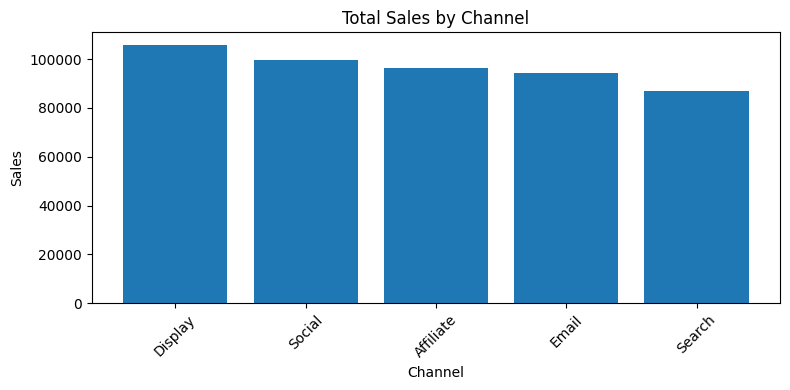

In [5]:
# Total Sales by Channel
sales_by_channel = (
    df.groupby("Channel", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)

plt.figure(figsize=(8, 4))
plt.bar(sales_by_channel["Channel"], sales_by_channel["Sales"])
plt.title("Total Sales by Channel")
plt.xlabel("Channel")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

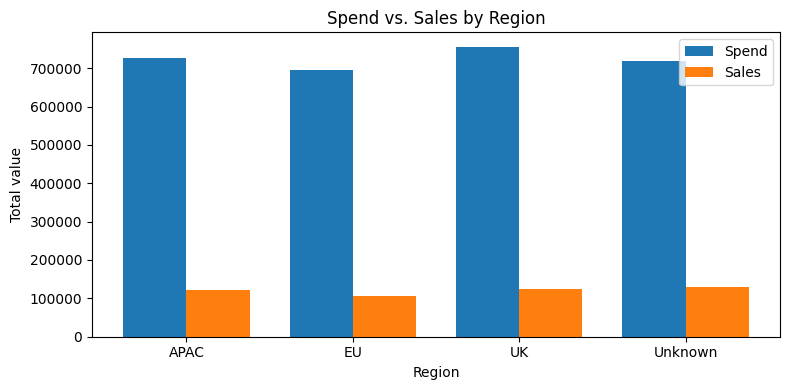

In [6]:
# Spend vs. Sales by Region
region_totals = df.groupby("Region")[["Spend", "Sales"]].sum()
x = np.arange(len(region_totals.index))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width / 2, region_totals["Spend"], width, label="Spend")
ax.bar(x + width / 2, region_totals["Sales"], width, label="Sales")
ax.set_xticks(x)
ax.set_xticklabels(region_totals.index)
ax.set_title("Spend vs. Sales by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Total value")
ax.legend()
plt.tight_layout()
plt.show()

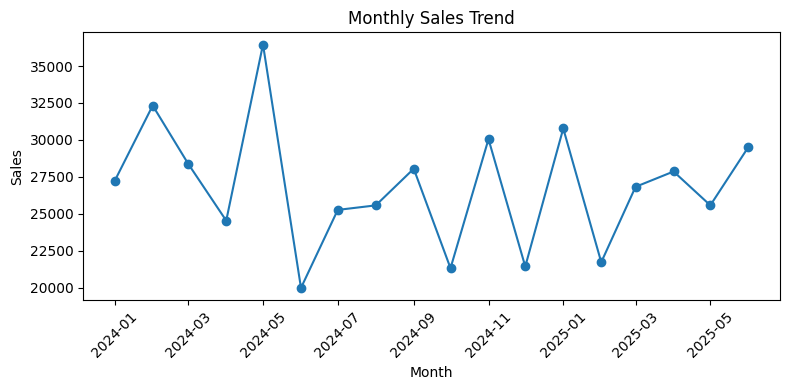

In [ ]:
# Monthly sales trend
monthly_sales = (
    df.assign(region=pd.to_datetime(df["Month"]))
    .groupby("_Month", as_index=False)["Sales"]
    .sum()
    .sort_values("_Month")
)

plt.figure(figsize=(8, 4))
plt.plot(monthly_sales["_Month"], monthly_sales["Sales"], marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Spend vs. Sales scatter plot
plt.figure(figsize=(6, 4))
plt.scatter(df["Spend"], df["Sales"], alpha=0.7)
plt.title("Spend vs. Sales")
plt.xlabel("Spend")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [ ]:
# Correlations among numeric marketing measures
numeric_columns = ["Spend", "Leads", "Sales", "Impressions", "Clicks"]
correlation = df[numeric_columns].corr()
display(correlation)

plt.figure(figsize=(7, 6))
plt.imshow(correlation, interpolation="nearest", aspect="auto", cmap="Reds")
plt.title("Correlation Heatmap")
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.tight_layout()
plt.show()

## 3. Homework exercises

Complete each code cell and answer each interpretation prompt. When calculating a group-level ratio, aggregate the numerator and denominator first, then divide. A zero denominator should produce an undefined value (`NaN`), not an error or an infinite rate.

### Q1. Channel CTR and CPL

Compute **CTR = Clicks / Impressions** and **CPL = Spend / Leads** (handle division by zero). Which channel has the best CTR and lowest CPL?

For each channel, calculate the ratios from the channel's total clicks, impressions, spend, and leads. Then identify the channel with the highest CTR and the channel with the lowest CPL. Note whether those are the same channel.

In [8]:
# Q1.Compute CTR = Clicks / Impressions and CPL = Spend / Leads (handle division by zero). Which channel has the best CTR and lowest CPL? 

## compute CTR and CPL and saved into new dataframe tmp
tmp = df.copy()
tmp['CTR'] = tmp['Clicks'] / tmp['Impressions'].replace(0, np.nan)
tmp['CPL'] = tmp['Spend'] / tmp['Leads'].replace(0, np.nan)

## compute each CTR and CPL by channel
by_chan = (
    tmp.groupby('Channel', as_index = False)[['CTR','CPL']]
        .mean()
        .sort_values('CTR', ascending=False)
)
print(by_chan)

## find out the Channel with highest CTR
max_ctr_channel = by_chan.loc[by_chan['CTR'].idxmax(), 'Channel']
print("The Channel with highest CTR is:", max_ctr_channel)

## find out the channel with lowest CPL 
min_cpl_channel = by_chan.loc[by_chan['CPL'].idxmin(), 'Channel']
print("The Channel with lowest CPL is:", min_cpl_channel)

     Channel       CTR        CPL
1    Display  0.031215  81.130797
4     Social  0.030580  85.991501
3     Search  0.030204  91.635343
0  Affiliate  0.029116  81.593207
2      Email  0.028260  80.360485
The Channel with highest CTR is: Display
The Channel with lowest CPL is: Email


**Response:**

- Best CTR channel and value:
- Lowest CPL channel and value:
- Are they the same channel? Explain briefly.

### Q2. Sales-to-Spend by Region

Which region achieves the highest **overall Sales-to-Spend ratio**? Aggregate total Sales and total Spend by region before dividing, then compare the ratios.

In [9]:
# Q2. Which region achieves the highest Sales-to-Spend ratio overall?

## compute the sales and spend by region:
by_region = df.groupby('Region')[['Sales','Spend']].sum()

## compute the sales/spend ratio per region:
by_region['Sales_to_Spend'] = by_region['Sales'] / by_region['Spend']

## sort highest ratio out:
print(by_region.sort_values('Sales_to_Spend', ascending=False))

## printing the highest ratio of region:
max_ratio_region = by_region['Sales_to_Spend'].idxmax()
print("The highest ratio of region is:", max_ratio_region)

             Sales      Spend  Sales_to_Spend
Region                                       
Unknown  130166.07  718512.27        0.181161
APAC     122861.71  726116.28        0.169204
UK       124812.56  755623.39        0.165178
EU       105034.23  694054.78        0.151334
The highest ratio of region is: Unknown


**Response:** Which region has the highest Sales-to-Spend ratio? State the ratio and briefly describe how you calculated it.

### Q3. Impressions vs. Clicks

Plot **Impressions vs Clicks** as a scatter plot. What relationship do you observe? Describe its direction, strength, and any notable spread or outliers.

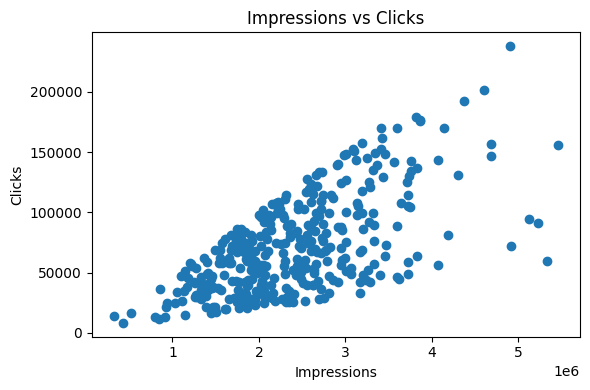

In [10]:
#Q3. Impressions vs Clicks Scatter
plt.figure(figsize=(6,4))
plt.scatter(df['Impressions'], df['Clicks'])
plt.xlabel('Impressions')
plt.ylabel('Clicks')
plt.title('Impressions vs Clicks')
plt.tight_layout()
plt.show()

#Expected: strong positive relationship; slope magnitude linked to CTR.

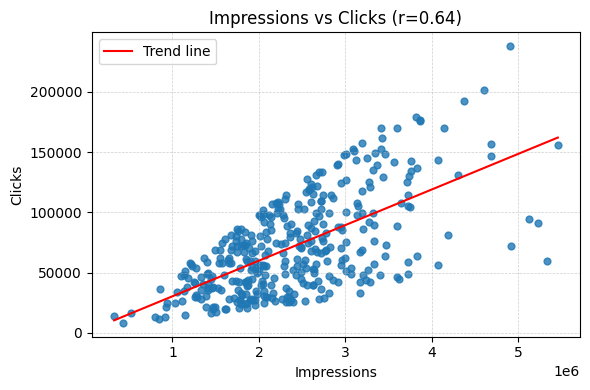

In [11]:
# compute ctr
y = df['Clicks']
x = df['Impressions']
ctr = y / x.replace(0, np.nan)

s, i = np.polyfit(x, y, 1)
line = np.linspace(x.min(), x.max(), 100)
r = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(x, y, s=24, alpha=0.8)
ax.plot(line, s*line + i, color = 'red', label = 'Trend line')
ax.set_title(f'Impressions vs Clicks (r={r:.2f})')
ax.set_xlabel('Impressions')
ax.set_ylabel('Clicks')
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.legend()
plt.show()

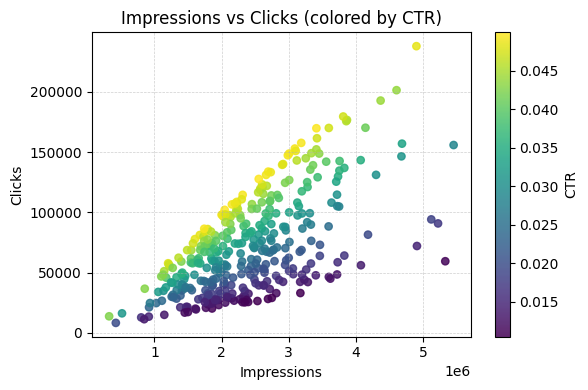

In [12]:
# plot degree of ctr for "Impressions vs Clicks"
fig, ax = plt.subplots(figsize=(6,4))
sc = ax.scatter(x, y, c=ctr, cmap='viridis', s=28, alpha=0.85)
plt.colorbar(sc, ax=ax, label='CTR')
ax.set_xlabel('Impressions')
ax.set_ylabel('Clicks')
ax.set_title('Impressions vs Clicks (colored by CTR)')
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

**Response:** Describe the relationship you see in the scatter plot. If helpful, refer to the correlation matrix above.

### Q4. Top 5 Channels by Total Sales

Re-plot **Total Sales by Channel**, but show only the top 5 channels by total Sales. Sort the aggregated results before selecting the top five.

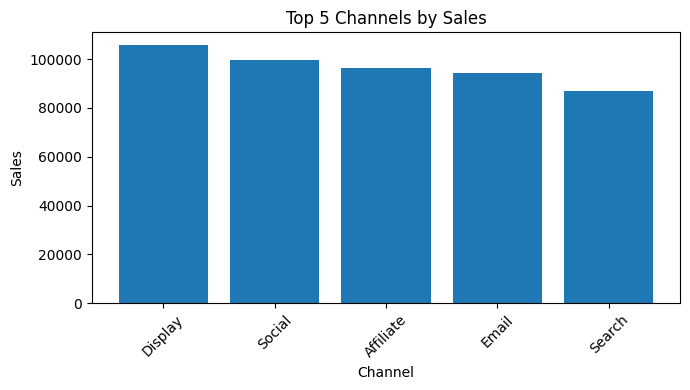

In [13]:
#Q4. Top-5 Channels by Sales (Bar)
top5_channel = df.groupby('Channel')['Sales'].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(7,4))
plt.bar(top5_channel.index, top5_channel.values)
plt.title('Top 5 Channels by Sales')
plt.xlabel('Channel')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Q5. Actionable Recommendation

Identify **one actionable recommendation** for the marketing team based on the trends and correlations you explored. Support it with at least one specific finding from your analysis, and explain what action the team should take.

**Recommendation:**

>